In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Visual Configuration
sns.set_theme(style="whitegrid")
pd.options.display.float_format = '{:,.2f}'.format
plt.rcParams['figure.dpi'] = 110
plt.rcParams['figure.figsize'] = (12, 6)

print("✅ Environment setup complete.")

✅ Environment setup complete.


1. Data Loading

In [28]:
print("🔄 Loading datasets...")

try:
    drivers = pd.read_csv('drivers.csv', na_values='\\N')
    results = pd.read_csv('results.csv', na_values='\\N')
    status = pd.read_csv('status.csv', na_values='\\N')

    # Using full dataset. If RAM issues occur, add nrows=100000
    lap_times = pd.read_csv('lap_times.csv')

    print(f"✅ Data loaded. Lap times records: {len(lap_times):,}")

except FileNotFoundError:
    print("❌ Error: Files not found. Please upload drivers.csv, results.csv, status.csv, and lap_times.csv.")

🔄 Loading datasets...
✅ Data loaded. Lap times records: 589,081


2. Master Data Preparation

In [29]:
# Merge Results with Driver Info
df = pd.merge(results, drivers, on='driverId')

# Merge with Status (for DNF analysis)
df = pd.merge(df, status, on='statusId')

# Formatting
df['driver_name'] = df['forename'] + " " + df['surname']
df['points'] = pd.to_numeric(df['points'], errors='coerce').fillna(0)

print("✅ Master dataframe created.")
df.head(3)

✅ Master dataframe created.


,resultId,raceId,driverId,constructorId,number_x,grid,position,positionText,positionOrder,points,...,driverRef,number_y,code,forename,surname,dob,nationality,url,status,driver_name
0,1,18,1,1,22.00,1,1.00,1,1,10.00,...,hamilton,44.00,HAM,Lewis,Hamilton,1985-01-07,British,http://en.wikipedia.org/wiki/Lewis_Hamilton,Finished,Lewis Hamilton
1,2,18,2,2,3.00,5,2.00,2,2,8.00,...,heidfeld,NaN,HEI,Nick,Heidfeld,1977-05-10,German,http://en.wikipedia.org/wiki/Nick_Heidfeld,Finished,Nick Heidfeld
2,3,18,3,3,7.00,7,3.00,3,3,6.00,...,rosberg,6.00,ROS,Nico,Rosberg,1985-06-27,German,http://en.wikipedia.org/wiki/Nico_Rosberg,Finished,Nico Rosberg


3. Analysis: Driver Profiling (Clustering)

In [30]:
# Aggregate driver stats
driver_stats = df.groupby('driver_name').agg({
    'raceId': 'count',
    'points': 'sum',
    'positionOrder': lambda x: (x == 1).sum()
}).reset_index()

driver_stats.columns = ['Driver Name', 'Total Races', 'Total Points', 'Total Wins']

# Filter: Experienced drivers only (>20 races)
driver_stats = driver_stats[driver_stats['Total Races'] > 20].copy()

# Calculate Metrics
driver_stats['Points Per Race'] = driver_stats['Total Points'] / driver_stats['Total Races']
driver_stats['Win Rate'] = driver_stats['Total Wins'] / driver_stats['Total Races']

# K-Means Clustering
scaler = StandardScaler()
X_scaled = scaler.fit_transform(driver_stats[['Points Per Race', 'Win Rate']])

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
driver_stats['cluster_id'] = kmeans.fit_predict(X_scaled)

# Intelligent Naming (Ranked by Win Rate)
cluster_rank = driver_stats.groupby('cluster_id')['Win Rate'].mean().sort_values(ascending=False).index
category_map = {
    cluster_rank[0]: "Dominant Legends",
    cluster_rank[1]: "Podium Contenders",
    cluster_rank[2]: "Midfielders",
    cluster_rank[3]: "Backmarkers"
}
driver_stats['Category'] = driver_stats['cluster_id'].map(category_map)

print("✅ Clustering complete. Drivers categorized.")

✅ Clustering complete. Drivers categorized.


4. Analysis: Consistency & Reliability

In [31]:
# --- Part A: Consistency (Lap Time Std Dev) ---
print("⏱️ Processing Lap Time Consistency...")
laps_merged = pd.merge(lap_times, drivers[['driverId', 'forename', 'surname']], on='driverId')
laps_merged['driver_name'] = laps_merged['forename'] + " " + laps_merged['surname']

# Filter outliers (Safety cars/Pitstops > 150s)
laps_clean = laps_merged[laps_merged['milliseconds'] < 150000]

# Calculate Consistency
consistency_per_race = laps_clean.groupby(['driver_name', 'raceId'])['milliseconds'].std().reset_index()
career_consistency = consistency_per_race.groupby('driver_name')['milliseconds'].mean().reset_index()
career_consistency.columns = ['Driver Name', 'Avg_Lap_StdDev']

# Merge to main stats
full_stats = pd.merge(driver_stats, career_consistency, on='Driver Name', how='inner')


# --- Part B: Reliability (DNF Analysis) ---
print("💥 Processing DNF Reasons...")

def classify_dnf(status_str):
    status_str = str(status_str).lower()
    if status_str in ['finished', '+1 lap', '+2 laps', '+3 laps', '+4 laps', '+5 laps']:
        return 'Finished'
    elif any(x in status_str for x in ['collision', 'accident', 'spun', 'run off']):
        return 'Accident/Driver Error'
    elif any(x in status_str for x in ['engine', 'gearbox', 'brakes', 'suspension', 'hydraulics', 'clutch', 'electrical']):
        return 'Car/Mechanical Failure'
    else:
        return 'Other'

df['DNF_Reason'] = df['status'].apply(classify_dnf)

print("✅ Advanced metrics calculated.")

⏱️ Processing Lap Time Consistency...
💥 Processing DNF Reasons...
✅ Advanced metrics calculated.


5. Visualization: Consistency & Reliability

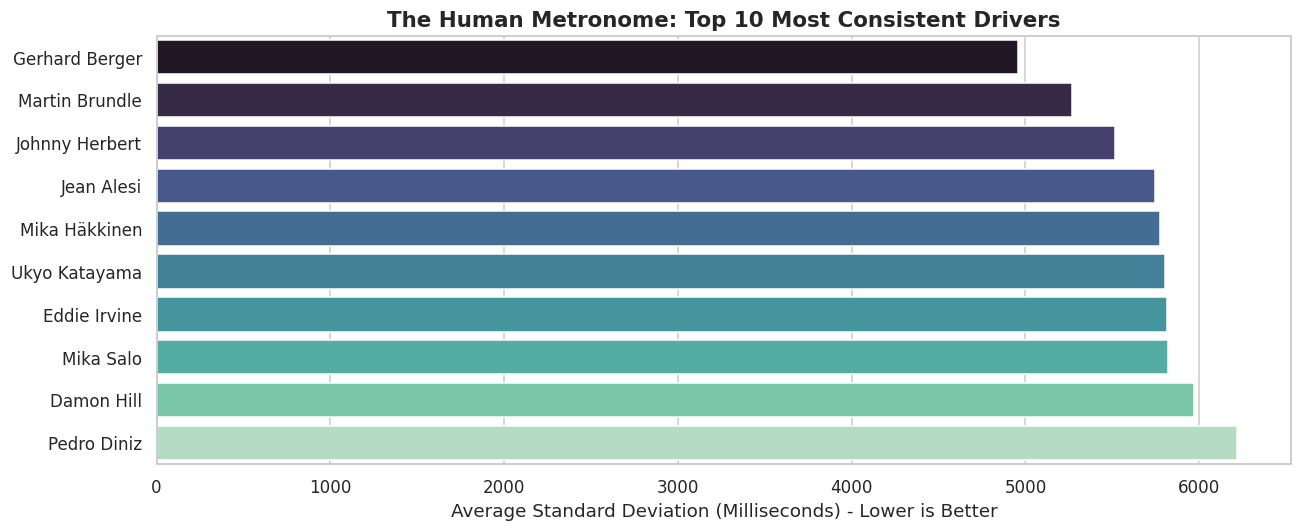

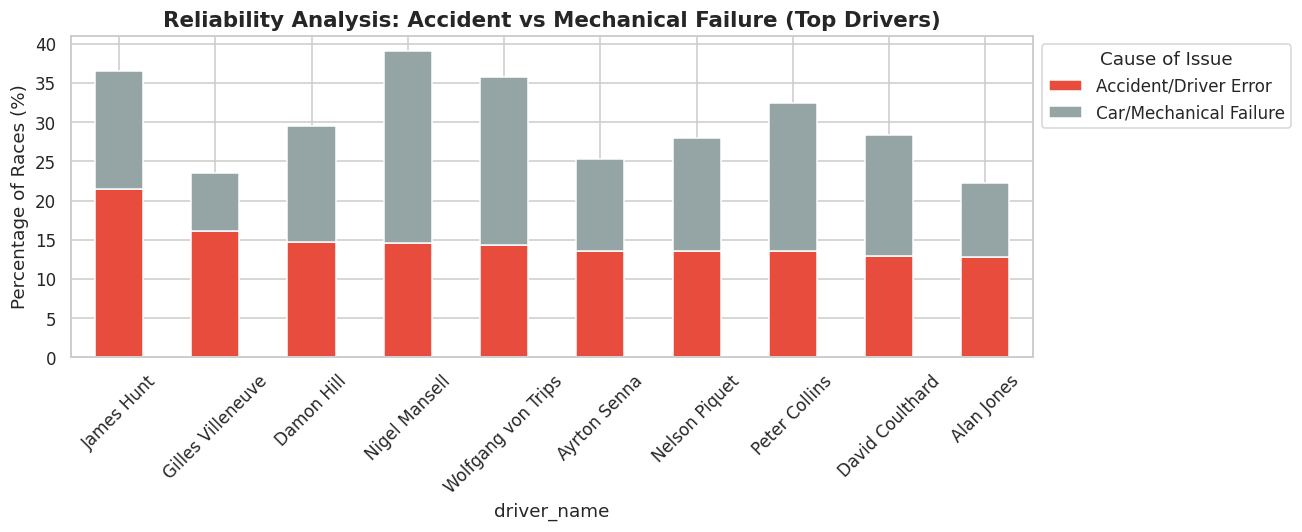

In [32]:
# Chart 1: The Human Metronome
top_consistent = full_stats[full_stats['Total Races'] > 50].sort_values('Avg_Lap_StdDev', ascending=True).head(10)

plt.figure(figsize=(12, 5))
sns.barplot(data=top_consistent, x='Avg_Lap_StdDev', y='Driver Name', hue='Driver Name', palette='mako', legend=False)
plt.title('The Human Metronome: Top 10 Most Consistent Drivers', fontsize=14, weight='bold')
plt.xlabel('Average Standard Deviation (Milliseconds) - Lower is Better')
plt.ylabel(None)
plt.tight_layout()
plt.show()

# Chart 2: Reliability Analysis
top_drivers_list = driver_stats[driver_stats['Category'].isin(['Dominant Legends', 'Podium Contenders'])]['Driver Name'].tolist()
dnf_data = df[df['driver_name'].isin(top_drivers_list)]

dnf_counts = dnf_data.groupby(['driver_name', 'DNF_Reason']).size().unstack().fillna(0)
dnf_pct = dnf_counts.div(dnf_counts.sum(axis=1), axis=0) * 100
dnf_pct_sorted = dnf_pct.sort_values('Accident/Driver Error', ascending=False).head(10)

dnf_pct_sorted[['Accident/Driver Error', 'Car/Mechanical Failure']].plot(
    kind='bar', stacked=True, figsize=(12, 5), color=['#e74c3c', '#95a5a6']
)
plt.title('Reliability Analysis: Accident vs Mechanical Failure (Top Drivers)', fontsize=14, weight='bold')
plt.ylabel('Percentage of Races (%)')
plt.legend(title='Cause of Issue', bbox_to_anchor=(1.0, 1.0))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

6. Visualization: Performance Matrix

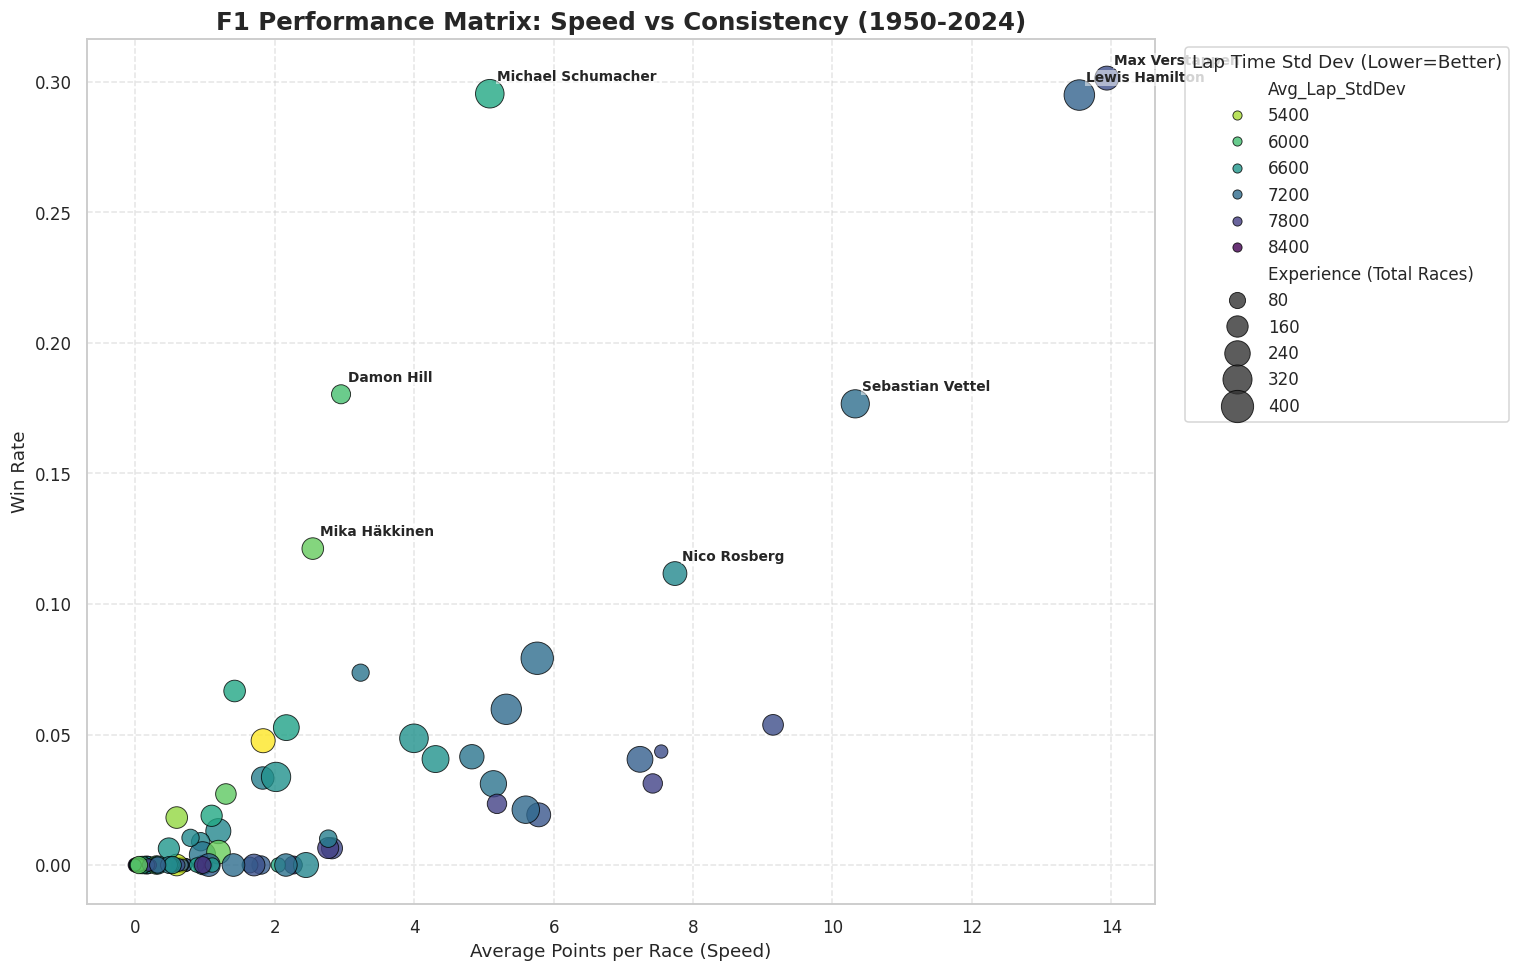

In [ ]:
# Rename column for Legend clarity
plot_data = full_stats.rename(columns={'Total Races': 'Experience (Total Races)'})

plt.figure(figsize=(14, 9))
sns.scatterplot(
    data=plot_data,
    x='Points Per Race',
    y='Win Rate',
    hue='Avg_Lap_StdDev',
    palette='viridis_r',
    size='Experience (Total Races)',
    sizes=(50, 450),
    alpha=0.8,
    edgecolor='black'
)

# Labeling notable drivers
notable = plot_data[
    (plot_data['Win Rate'] > 0.1) | (plot_data['Avg_Lap_StdDev'] < 1500)
]

for i in range(len(notable)):
    plt.text(
        x=notable.iloc[i]['Points Per Race'] + 0.1,
        y=notable.iloc[i]['Win Rate'] + 0.005,
        s=notable.iloc[i]['Driver Name'],
        fontsize=9, weight='bold',
        bbox=dict(facecolor='white', alpha=0.5, edgecolor='none', pad=0.5)
    )

plt.title('F1 Performance Matrix: Speed vs Consistency (1950-2024)', fontsize=16, weight='bold')
plt.xlabel('Average Points per Race (Speed)')
plt.ylabel('Win Rate')
plt.legend(title='Lap Time Std Dev (Lower=Better)', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()